# 04 — PPG + IMU Sensor Fusion Model

This notebook evaluates a Deep Learning sensor-fusion approach for heart-rate estimation using PPG and three-axis accelerometer data.

## Input

Each 8-second window contains:

- `PPG_Raw`
- `ACC_X`
- `ACC_Y`
- `ACC_Z`

Input shape: `(N, 320, 4)`

## Target

The regression target is the mean chest-strap heart rate within the same 8-second window.

## Experimental Setup

For a fair comparison with the PPG-only baseline, this experiment uses:

- the same raw recordings
- the same exact 8-second windows
- the same train / validation / test split
- the same target definition
- the same main CNN architecture

The main difference is the addition of the three accelerometer channels to the PPG input.

## Evaluation

Performance is evaluated using overall regression metrics as well as activity-specific results.

An activity-mean diagnostic baseline is also included to examine whether model performance is influenced by activity-dependent heart-rate levels.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Re-run the Final Preprocessing Pipeline

This executes `02_preprocessing_windowing.ipynb` in the same notebook namespace.

It recreates the exact same windows and splits used for the PPG-only experiment.

In [2]:
%%capture preprocessing_output
%run ./02_preprocessing_windowing.ipynb

## 3. Confirm Fusion Input Shapes

In [3]:
print("Train:", X_fusion_train.shape, y_train.shape)
print("Val  :", X_fusion_val.shape, y_val.shape)
print("Test :", X_fusion_test.shape, y_test.shape)

assert X_fusion_train.shape[1:] == (320, 4)
assert X_fusion_val.shape[1:] == (320, 4)
assert X_fusion_test.shape[1:] == (320, 4)

print("PPG + IMU input shapes are correct.")

Train: (1322, 320, 4) (1322,)
Val  : (281, 320, 4) (281,)
Test : (292, 320, 4) (292,)
PPG + IMU input shapes are correct.


## 4. Training-Only Per-Channel Normalization

PPG and accelerometer channels have very different numerical scales.

Therefore each input channel is normalized separately using only the **training set**:

`x_norm = (x - train_mean) / train_std`

Validation and test data use the same training statistics.

In [4]:
channel_names = [
    "PPG_Raw",
    "ACC_X",
    "ACC_Y",
    "ACC_Z",
]

train_channel_mean = X_fusion_train.mean(
    axis=(0, 1),
    keepdims=True
)

train_channel_std = X_fusion_train.std(
    axis=(0, 1),
    keepdims=True
)

if np.any(train_channel_std == 0):
    raise ValueError(
        "At least one training input channel has zero standard deviation."
    )

X_train_norm = (
    X_fusion_train
    - train_channel_mean
) / train_channel_std

X_val_norm = (
    X_fusion_val
    - train_channel_mean
) / train_channel_std

X_test_norm = (
    X_fusion_test
    - train_channel_mean
) / train_channel_std


normalization_table = pd.DataFrame({
    "Channel": channel_names,
    "Train_Mean": train_channel_mean.reshape(-1),
    "Train_Std": train_channel_std.reshape(-1),
    "Normalized_Train_Mean": X_train_norm.mean(
        axis=(0, 1)
    ),
    "Normalized_Train_Std": X_train_norm.std(
        axis=(0, 1)
    ),
})

display(
    normalization_table.round(5)
)

,Channel,Train_Mean,Train_Std,Normalized_Train_Mean,Normalized_Train_Std
0,PPG_Raw,4471.462402,1247.204712,0.00364,1.00000
1,ACC_X,-0.325390,0.557720,-0.00000,1.00000
2,ACC_Y,0.343380,0.233840,0.00004,0.99999
3,ACC_Z,-0.675510,0.319860,0.00006,0.99999


## 5. Visual Check of One Fusion Window

The plots below show the four normalized input channels from the same 8-second training window.

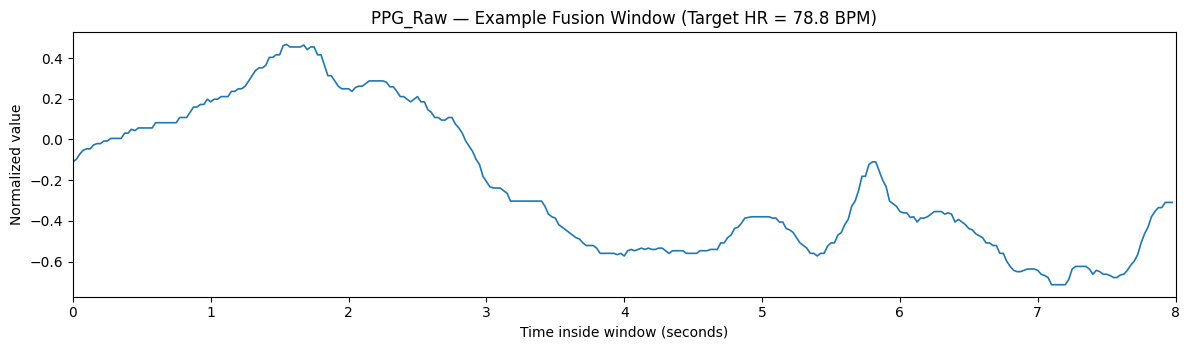

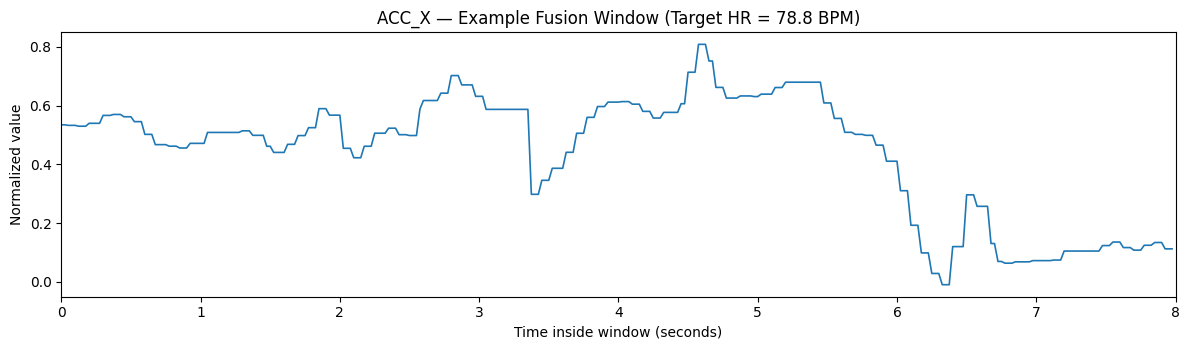

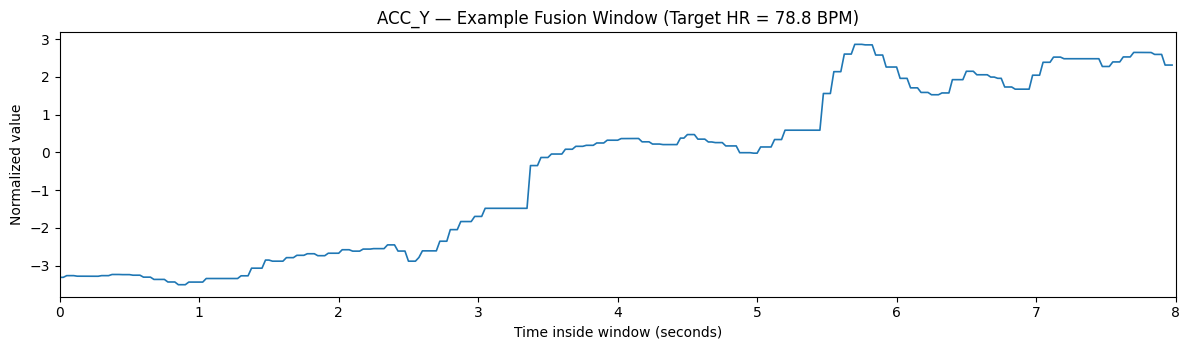

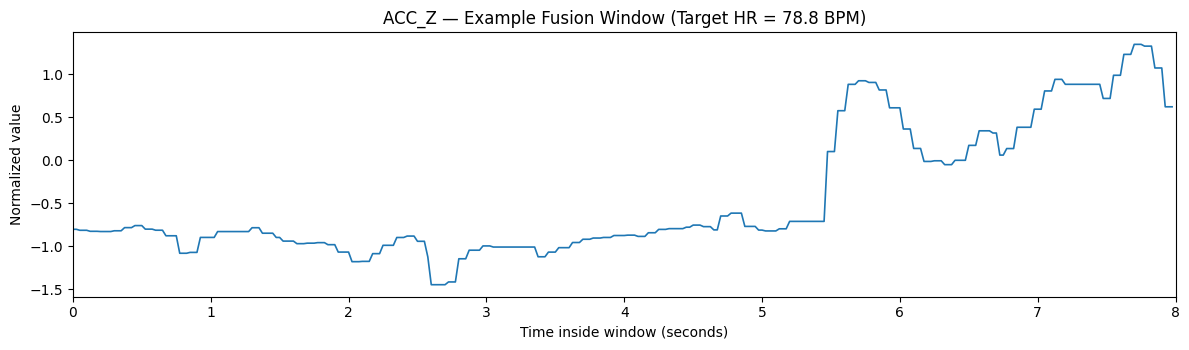

In [5]:
example_index = 0

time_axis = np.linspace(
    0,
    8,
    X_train_norm.shape[1],
    endpoint=False
)

for channel_index, channel_name in enumerate(channel_names):
    plt.figure(figsize=(12, 3.6))

    plt.plot(
        time_axis,
        X_train_norm[
            example_index,
            :,
            channel_index
        ],
        linewidth=1.2
    )

    plt.xlabel("Time inside window (seconds)")
    plt.ylabel("Normalized value")

    plt.title(
        f"{channel_name} — Example Fusion Window "
        f"(Target HR = {y_train[example_index]:.1f} BPM)"
    )

    plt.xlim(0, 8)
    plt.tight_layout()
    plt.show()

## 6. Reproducibility

In [6]:
SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 7. Build the Fusion 1D CNN

For a controlled comparison with the PPG-only baseline, the main architecture is kept the same.

The only structural change is:

- PPG-only input: `(320, 1)`
- Fusion input: `(320, 4)`

This lets the model learn temporal features jointly from PPG and the three accelerometer axes.

In [7]:
def build_fusion_model():
    inputs = tf.keras.layers.Input(
        shape=(320, 4),
        name="ppg_imu_input"
    )

    x = tf.keras.layers.Conv1D(
        32,
        kernel_size=7,
        padding="same",
        activation="relu"
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.MaxPooling1D(
        pool_size=2
    )(x)

    x = tf.keras.layers.Conv1D(
        64,
        kernel_size=5,
        padding="same",
        activation="relu"
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.MaxPooling1D(
        pool_size=2
    )(x)

    x = tf.keras.layers.Conv1D(
        128,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dropout(
        0.30
    )(x)

    x = tf.keras.layers.Dense(
        64,
        activation="relu"
    )(x)

    x = tf.keras.layers.Dropout(
        0.20
    )(x)

    outputs = tf.keras.layers.Dense(
        1,
        name="predicted_hr"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="PPG_IMU_Fusion_1D_CNN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


fusion_model = build_fusion_model()
fusion_model.summary()

Model: "PPG_IMU_Fusion_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ppg_imu_input (InputLayer)      │ (None, 320, 4)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 320, 32)        │           928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 320, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 160, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 160, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 80, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predicted_hr (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,641 (174.38 KB)

 Trainable params: 44,449 (173.63 KB)

 Non-trainable params: 192 (768.00 B)

## 8. Training Callbacks

In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=18,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=7,
        min_lr=1e-6,
        verbose=1,
    ),
]

## 9. Train the Fusion Model

The test set remains untouched until evaluation.

In [9]:
history = fusion_model.fit(
    X_train_norm,
    y_train,

    validation_data=(
        X_val_norm,
        y_val
    ),

    epochs=180,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 5048.9521 - mae: 62.9814 - val_loss: 5298.0698 - val_mae: 69.7586 - learning_rate: 0.0010
Epoch 2/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 432.0564 - mae: 16.3714 - val_loss: 3666.0361 - val_mae: 57.0485 - learning_rate: 0.0010
Epoch 3/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 378.2784 - mae: 15.4550 - val_loss: 2429.2959 - val_mae: 46.1340 - learning_rate: 0.0010
Epoch 4/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 338.7912 - mae: 14.6381 - val_loss: 1641.1071 - val_mae: 37.4070 - learning_rate: 0.0010
Epoch 5/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 316.3602 - mae: 14.0348 - val_loss: 1056.9436 - val_mae: 29.1205 - learning_rate: 0.0010
Epoch 6/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 315.2559 - mae: 14.1120 - val_loss: 555.1517 - val_mae: 20.8390 - learning_rate: 0.0010
Epoch 7/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 293.8016 - mae: 13.4313 - val_loss: 360.0033 - val

## 10. Training History

Epochs trained: 71
Best epoch    : 53


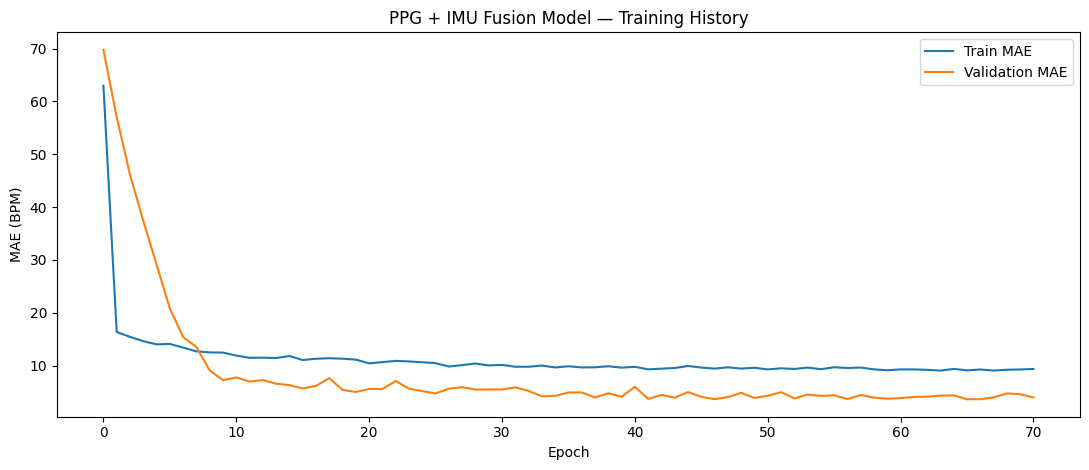

In [10]:
history_df = pd.DataFrame(
    history.history
)

best_epoch = int(
    history_df["val_loss"].idxmin()
    + 1
)

print("Epochs trained:", len(history_df))
print("Best epoch    :", best_epoch)

plt.figure(figsize=(11, 4.8))

plt.plot(
    history_df["mae"],
    label="Train MAE"
)

plt.plot(
    history_df["val_mae"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE (BPM)")
plt.title("PPG + IMU Fusion Model — Training History")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Test Predictions

In [11]:
y_pred_fusion = (
    fusion_model.predict(
        X_test_norm,
        verbose=0
    )
    .reshape(-1)
)

print(
    "Fusion predictions:",
    y_pred_fusion.shape
)

Fusion predictions: (292,)


## 12. Metric Function

In [12]:
def regression_metrics(
    y_true,
    y_prediction
):
    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_prediction = np.asarray(
        y_prediction,
        dtype=float
    )

    mae = mean_absolute_error(
        y_true,
        y_prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_prediction
        )
    )

    r2 = r2_score(
        y_true,
        y_prediction
    )

    if (
        len(y_true) > 1
        and np.std(y_true) > 0
        and np.std(y_prediction) > 0
    ):
        correlation = np.corrcoef(
            y_true,
            y_prediction
        )[0, 1]
    else:
        correlation = np.nan

    return {
        "MAE_BPM": mae,
        "RMSE_BPM": rmse,
        "R2": r2,
        "Correlation": correlation,
        "True_Mean": np.mean(y_true),
        "True_Std": np.std(y_true),
        "Pred_Mean": np.mean(y_prediction),
        "Pred_Std": np.std(y_prediction),
    }

## 13. Overall Fusion Test Metrics

In [13]:
fusion_overall_metrics = regression_metrics(
    y_test,
    y_pred_fusion
)

fusion_overall_results = pd.DataFrame([
    {
        "Model": "PPG + IMU Fusion 1D CNN",
        **fusion_overall_metrics,
    }
])

display(
    fusion_overall_results.round(3)
)

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,PPG + IMU Fusion 1D CNN,4.956,6.83,0.917,0.958,89.163,23.663,89.273,22.028


## 14. Global Train-Mean Baseline

This baseline predicts one constant HR value for every test window.

In [14]:
global_train_mean_hr = float(
    np.mean(y_train)
)

global_mean_pred = np.full(
    shape=len(y_test),
    fill_value=global_train_mean_hr,
    dtype=float
)

global_mean_metrics = regression_metrics(
    y_test,
    global_mean_pred
)

## 15. Activity-Mean Diagnostic Baseline

This diagnostic intentionally uses the activity label to predict only the training-set mean HR of that activity.

It is **not** a deployable HR-estimation model.

Its purpose is to reveal whether a high overall score can be explained simply by different activities having different typical HR levels.

In [15]:
train_activity = (
    meta_train[
        "Activity"
    ]
    .to_numpy()
)

test_activity = (
    meta_test[
        "Activity"
    ]
    .to_numpy()
)

activity_mean_map = {}

for activity in ACTIVITY_ORDER:
    mask = (
        train_activity
        == activity
    )

    if np.any(mask):
        activity_mean_map[
            activity
        ] = float(
            np.mean(
                y_train[mask]
            )
        )


activity_mean_pred = np.array(
    [
        activity_mean_map[
            activity
        ]
        for activity in test_activity
    ],
    dtype=float
)

activity_mean_metrics = regression_metrics(
    y_test,
    activity_mean_pred
)

diagnostic_comparison = pd.DataFrame([
    {
        "Model": "Global train-mean baseline",
        **global_mean_metrics,
    },
    {
        "Model": "Activity-mean diagnostic",
        **activity_mean_metrics,
    },
    {
        "Model": "PPG + IMU Fusion 1D CNN",
        **fusion_overall_metrics,
    },
])

display(
    diagnostic_comparison.round(3)
)

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Global train-mean baseline,21.293,23.836,-0.015,NaN,89.163,23.663,92.031,0.000
1,Activity-mean diagnostic,4.316,6.604,0.922,0.969,89.163,23.663,92.130,23.872
2,PPG + IMU Fusion 1D CNN,4.956,6.830,0.917,0.958,89.163,23.663,89.273,22.028


## 16. Per-Activity Fusion Metrics

This is one of the most important evaluations.

Strong overall R² or correlation is not sufficient if the model cannot follow HR variation **within the same activity**.

In [16]:
fusion_activity_rows = []

for activity in ACTIVITY_ORDER:
    mask = (
        test_activity
        == activity
    )

    if not np.any(mask):
        continue

    metrics = regression_metrics(
        y_test[mask],
        y_pred_fusion[mask]
    )

    fusion_activity_rows.append({
        "Activity": activity,
        "Test_Windows": int(
            mask.sum()
        ),
        **metrics,
    })


fusion_activity_results = pd.DataFrame(
    fusion_activity_rows
)

display(
    fusion_activity_results.round(3)
)

,Activity,Test_Windows,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Eating,8,8.893,10.962,-3.968,0.079,84.915,4.918,86.935,9.982
1,High_Tempo_Cycling,38,9.248,10.947,-0.238,-0.061,113.883,9.839,113.158,4.183
2,Low_Tempo_Cycling,56,5.336,6.640,-2.023,-0.397,112.126,3.819,112.990,4.056
3,Sitting,43,3.858,5.679,0.356,0.727,72.895,7.079,72.522,8.061
4,Sleep,73,3.709,4.097,-9.624,0.322,56.056,1.257,59.741,1.743
5,Walking,74,3.905,6.394,-3.405,0.013,101.662,3.046,98.181,4.454


## 17. Macro Within-Activity Metrics

In [17]:
macro_mae = float(
    fusion_activity_results[
        "MAE_BPM"
    ].mean()
)

macro_rmse = float(
    fusion_activity_results[
        "RMSE_BPM"
    ].mean()
)

macro_corr = float(
    fusion_activity_results[
        "Correlation"
    ].mean()
)

print(
    f"Macro activity MAE        : "
    f"{macro_mae:.3f} BPM"
)

print(
    f"Macro activity RMSE       : "
    f"{macro_rmse:.3f} BPM"
)

print(
    f"Macro activity correlation: "
    f"{macro_corr:.3f}"
)

Macro activity MAE        : 5.825 BPM
Macro activity RMSE       : 7.453 BPM
Macro activity correlation: 0.114


## 18. Activity-Mean vs Fusion MAE

If the fusion model only learns activity identity from the accelerometer, the simple activity-mean diagnostic may still outperform it.

A meaningful fusion improvement should therefore be checked activity by activity.

In [18]:
activity_baseline_rows = []

for activity in ACTIVITY_ORDER:
    mask = (
        test_activity
        == activity
    )

    if not np.any(mask):
        continue

    metrics = regression_metrics(
        y_test[mask],
        activity_mean_pred[mask]
    )

    activity_baseline_rows.append({
        "Activity": activity,
        "Activity_Mean_MAE": metrics[
            "MAE_BPM"
        ],
    })


activity_baseline_results = pd.DataFrame(
    activity_baseline_rows
)

fusion_mae_comparison = (
    activity_baseline_results
    .merge(
        fusion_activity_results[
            [
                "Activity",
                "MAE_BPM",
                "Correlation",
            ]
        ].rename(
            columns={
                "MAE_BPM": "Fusion_MAE",
                "Correlation": "Fusion_Correlation",
            }
        ),
        on="Activity"
    )
)

fusion_mae_comparison[
    "Fusion_Improvement_vs_ActivityMean_BPM"
] = (
    fusion_mae_comparison[
        "Activity_Mean_MAE"
    ]
    - fusion_mae_comparison[
        "Fusion_MAE"
    ]
)

display(
    fusion_mae_comparison.round(3)
)

,Activity,Activity_Mean_MAE,Fusion_MAE,Fusion_Correlation,Fusion_Improvement_vs_ActivityMean_BPM
0,Eating,4.353,8.893,0.079,-4.539
1,High_Tempo_Cycling,10.750,9.248,-0.061,1.501
2,Low_Tempo_Cycling,3.521,5.336,-0.397,-1.815
3,Sitting,5.516,3.858,0.727,1.658
4,Sleep,2.872,3.709,0.322,-0.838
5,Walking,2.336,3.905,0.013,-1.569


## 19. Ground Truth vs Fusion Prediction

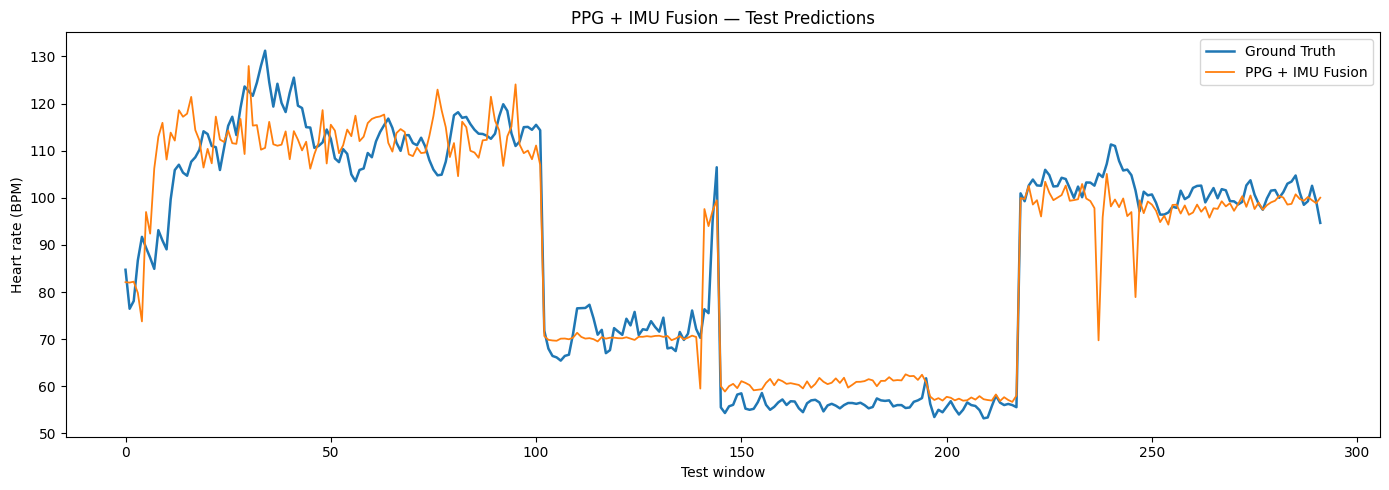

In [19]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test,
    label="Ground Truth",
    linewidth=1.8
)

plt.plot(
    y_pred_fusion,
    label="PPG + IMU Fusion",
    linewidth=1.3
)

plt.xlabel("Test window")
plt.ylabel("Heart rate (BPM)")
plt.title(
    "PPG + IMU Fusion — Test Predictions"
)

plt.legend()
plt.tight_layout()
plt.show()

## 20. Predicted vs True HR

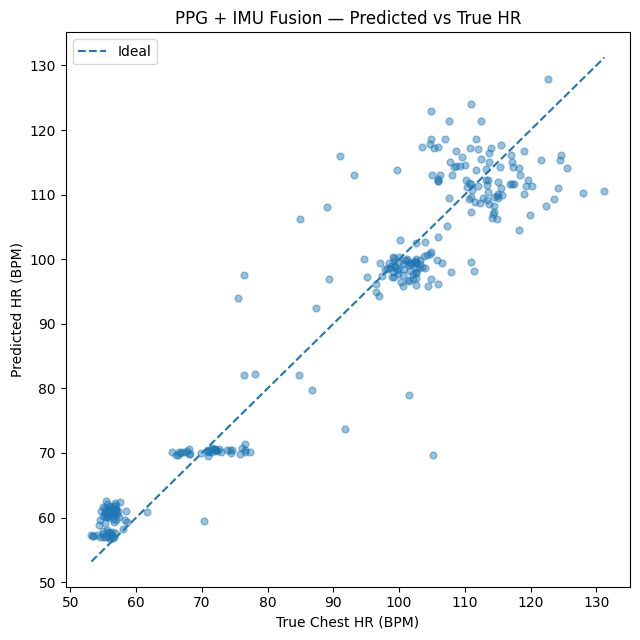

In [20]:
low = float(
    min(
        y_test.min(),
        y_pred_fusion.min()
    )
)

high = float(
    max(
        y_test.max(),
        y_pred_fusion.max()
    )
)

plt.figure(figsize=(6.5, 6.5))

plt.scatter(
    y_test,
    y_pred_fusion,
    s=24,
    alpha=0.45
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    linewidth=1.5,
    label="Ideal"
)

plt.xlabel("True Chest HR (BPM)")
plt.ylabel("Predicted HR (BPM)")
plt.title(
    "PPG + IMU Fusion — Predicted vs True HR"
)

plt.legend()
plt.tight_layout()
plt.show()

## 21. Per-Activity Fusion MAE

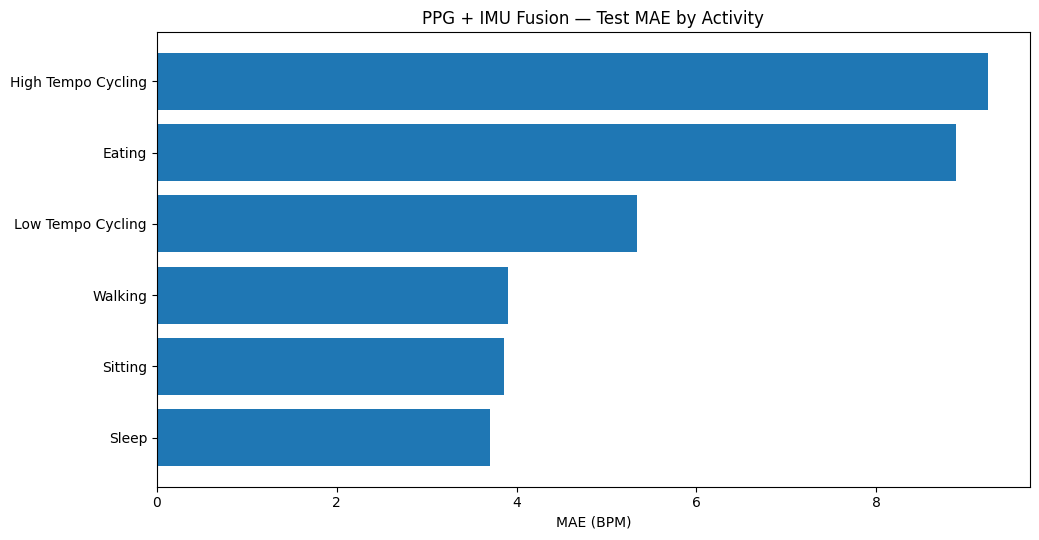

In [21]:
plot_df = fusion_activity_results.sort_values(
    "MAE_BPM"
)

plt.figure(figsize=(10.5, 5.5))

plt.barh(
    plot_df[
        "Activity"
    ].str.replace(
        "_",
        " "
    ),
    plot_df[
        "MAE_BPM"
    ]
)

plt.xlabel("MAE (BPM)")
plt.title(
    "PPG + IMU Fusion — Test MAE by Activity"
)

plt.tight_layout()
plt.show()

## 22. Per-Activity Fusion Correlation

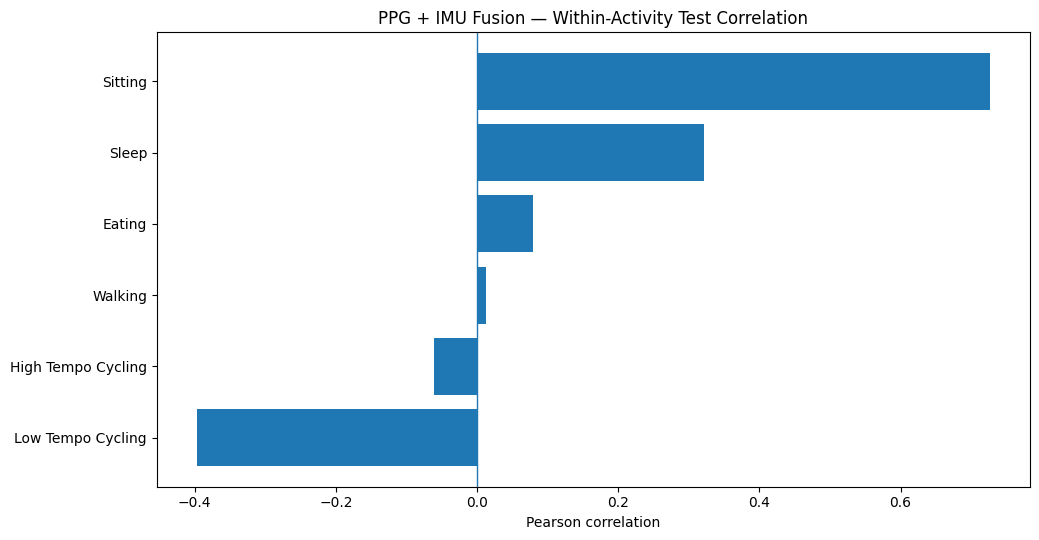

In [22]:
plot_df = fusion_activity_results.sort_values(
    "Correlation"
)

plt.figure(figsize=(10.5, 5.5))

plt.barh(
    plot_df[
        "Activity"
    ].str.replace(
        "_",
        " "
    ),
    plot_df[
        "Correlation"
    ]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Pearson correlation")
plt.title(
    "PPG + IMU Fusion — Within-Activity Test Correlation"
)

plt.tight_layout()
plt.show()

## 23. Activity-Mean Baseline vs Fusion

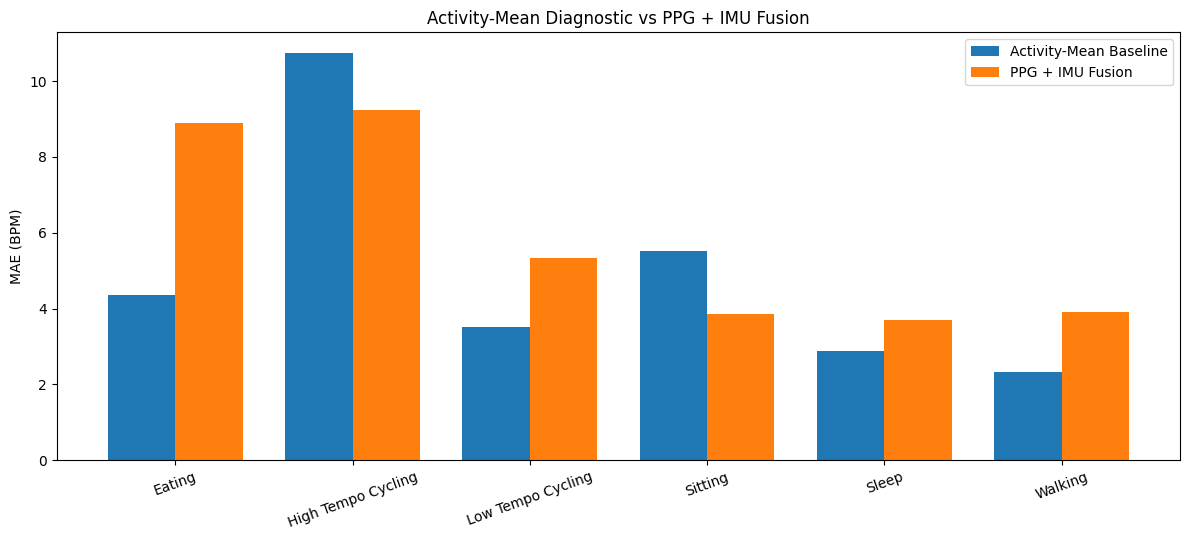

In [23]:
x = np.arange(
    len(
        fusion_mae_comparison
    )
)

width = 0.38

plt.figure(figsize=(12, 5.5))

plt.bar(
    x - width / 2,
    fusion_mae_comparison[
        "Activity_Mean_MAE"
    ],
    width,
    label="Activity-Mean Baseline"
)

plt.bar(
    x + width / 2,
    fusion_mae_comparison[
        "Fusion_MAE"
    ],
    width,
    label="PPG + IMU Fusion"
)

plt.xticks(
    x,
    fusion_mae_comparison[
        "Activity"
    ].str.replace(
        "_",
        " "
    ),
    rotation=20
)

plt.ylabel("MAE (BPM)")

plt.title(
    "Activity-Mean Diagnostic vs PPG + IMU Fusion"
)

plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Early Fusion CNN - Per-Activity HR Accuracy Rates

rows = []

for activity in ACTIVITY_ORDER:
    mask = test_activity == activity

    true_hr = y_test[mask]
    pred_hr = y_pred_fusion[mask]

    errors = np.abs(true_hr - pred_hr)

    rows.append({
        "Activity": activity,
        "Samples": len(true_hr),
        "MAE_BPM": np.mean(errors),
        "RMSE_BPM": np.sqrt(np.mean(errors**2)),
        "Within_5_BPM_%": np.mean(errors <= 5) * 100,
        "Within_10_BPM_%": np.mean(errors <= 10) * 100
    })

fusion_activity_accuracy = pd.DataFrame(rows)

display(fusion_activity_accuracy.round(2))

,Activity,Samples,MAE_BPM,RMSE_BPM,Within_5_BPM_%,Within_10_BPM_%
0,Eating,8,8.89,10.96,25.00,75.00
1,High_Tempo_Cycling,38,9.25,10.95,23.68,63.16
2,Low_Tempo_Cycling,56,5.34,6.64,46.43,87.50
3,Sitting,43,3.86,5.68,76.74,93.02
4,Sleep,73,3.71,4.10,75.34,100.00
5,Walking,74,3.91,6.39,81.08,94.59


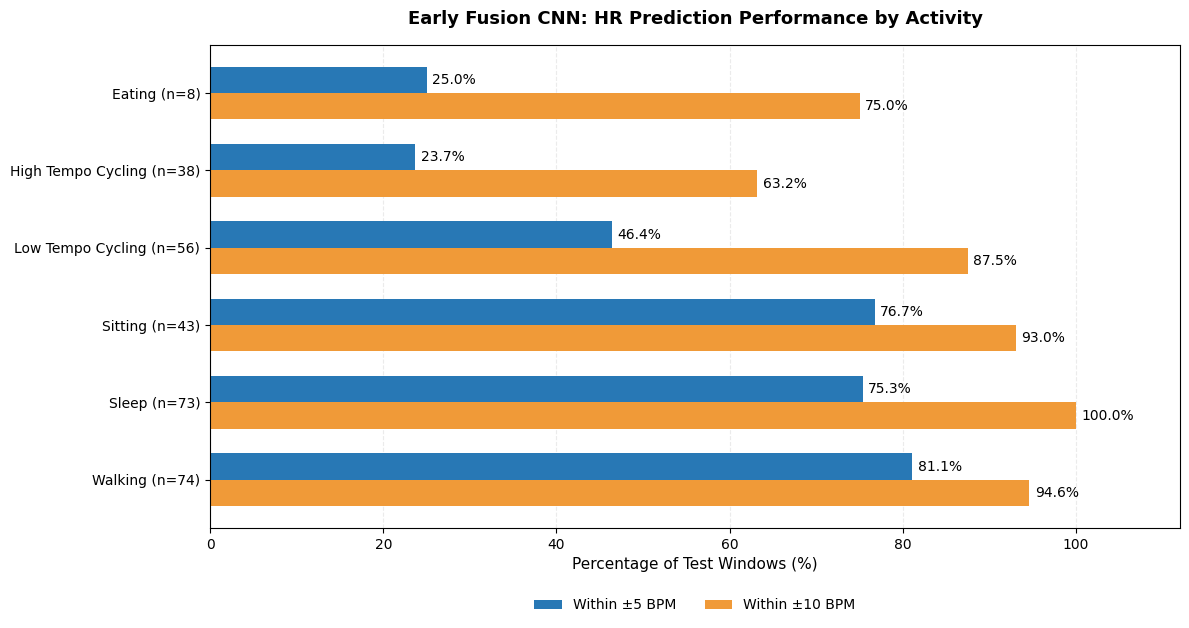

In [27]:

# Early Fusion CNN — Per-Activity HR Prediction Performance

import numpy as np
import matplotlib.pyplot as plt

# Prepare data
plot_df = fusion_activity_accuracy.copy()

plot_df["Activity"] = (
    plot_df["Activity"].str.replace("_", " ")
)

y = np.arange(len(plot_df))
height = 0.34

# Create figure
fig, ax = plt.subplots(figsize=(12, 6.5))

# Within ±5 BPM
bars5 = ax.barh(
    y - height / 2,
    plot_df["Within_5_BPM_%"],
    height,
    label="Within ±5 BPM",
    color="#2878B5"
)

# Within ±10 BPM
bars10 = ax.barh(
    y + height / 2,
    plot_df["Within_10_BPM_%"],
    height,
    label="Within ±10 BPM",
    color="#F09A38"
)

# Add percentage labels
ax.bar_label(
    bars5,
    fmt="%.1f%%",
    padding=4,
    fontsize=10
)

ax.bar_label(
    bars10,
    fmt="%.1f%%",
    padding=4,
    fontsize=10
)

# Activity names and test sample counts
labels = [
    f"{activity} (n={n})"
    for activity, n in zip(
        plot_df["Activity"],
        plot_df["Samples"]
    )
]

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10)

ax.set_xlim(0, 112)
ax.set_xticks(np.arange(0, 101, 20))
ax.invert_yaxis()

# Axis labels and title
ax.set_xlabel(
    "Percentage of Test Windows (%)",
    fontsize=11
)

ax.set_title(
    "Early Fusion CNN: HR Prediction Performance by Activity",
    fontsize=13,
    fontweight="bold",
    pad=15
)

# Legend below the chart
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
    fontsize=10
)

# Grid
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(bottom=0.18)

# Save high-resolution image
plt.savefig(
    "early_fusion_activity_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

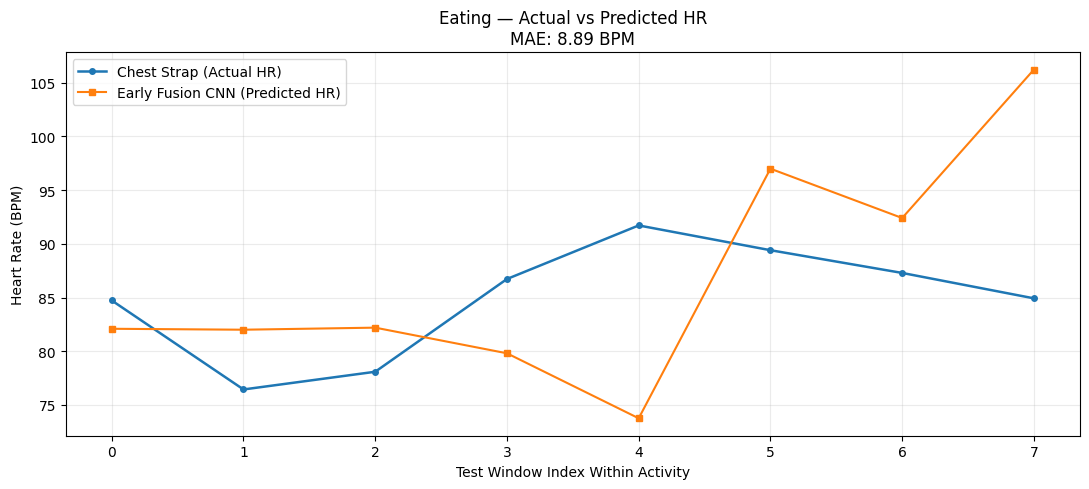

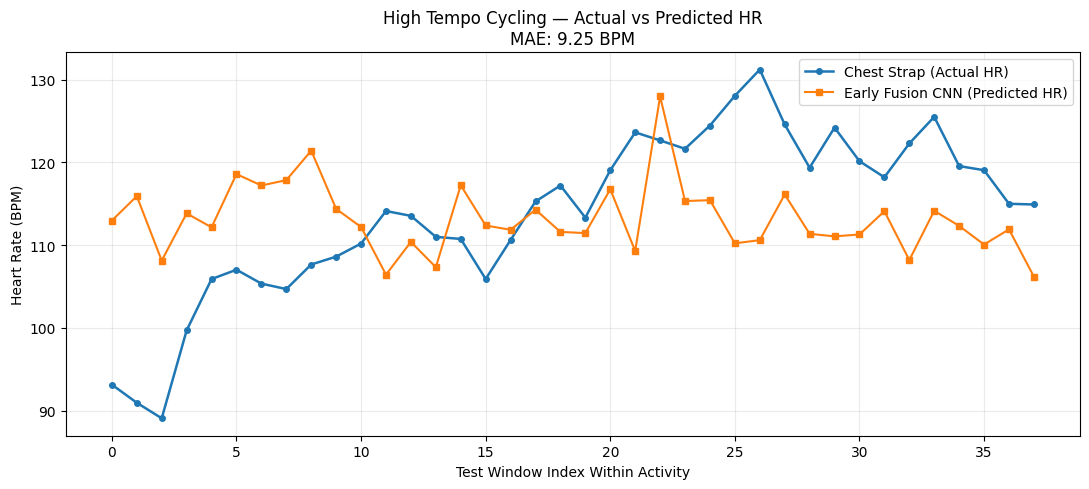

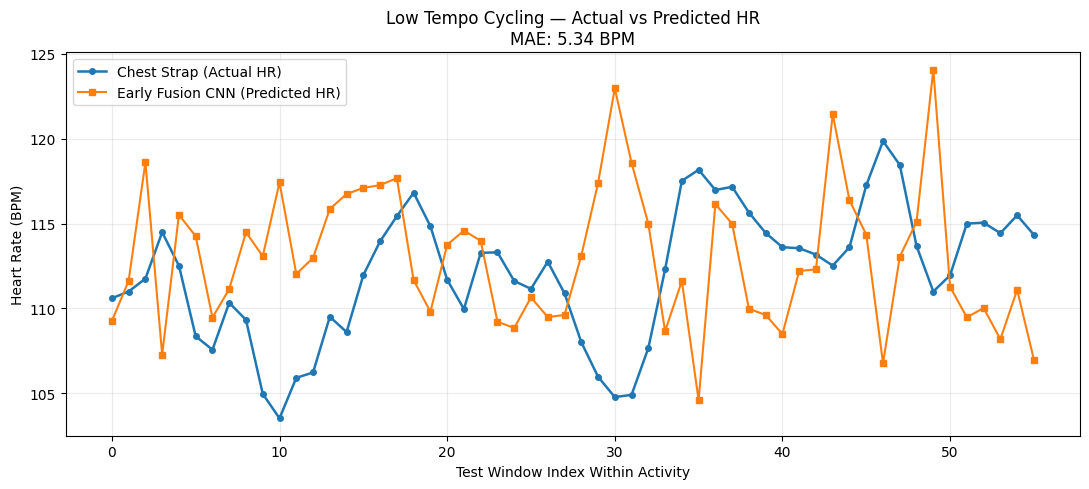

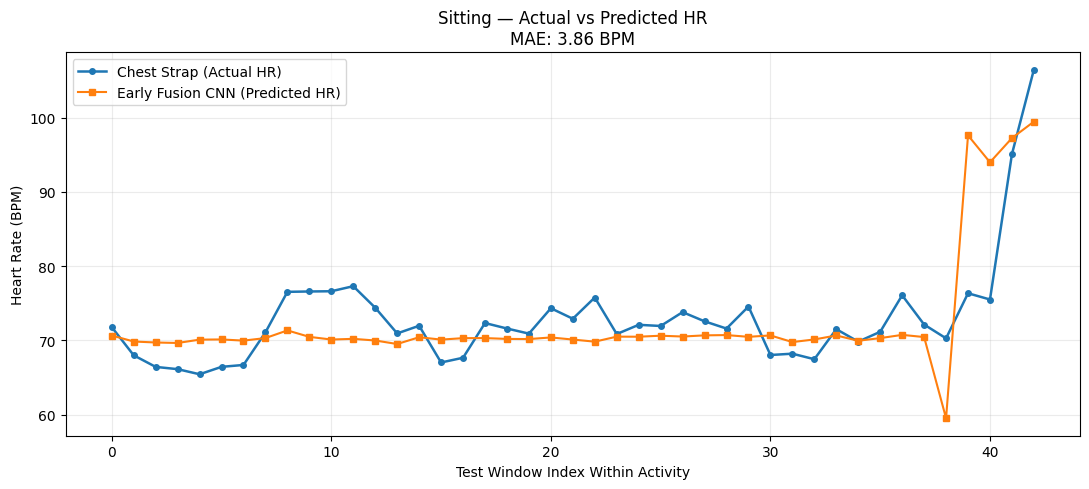

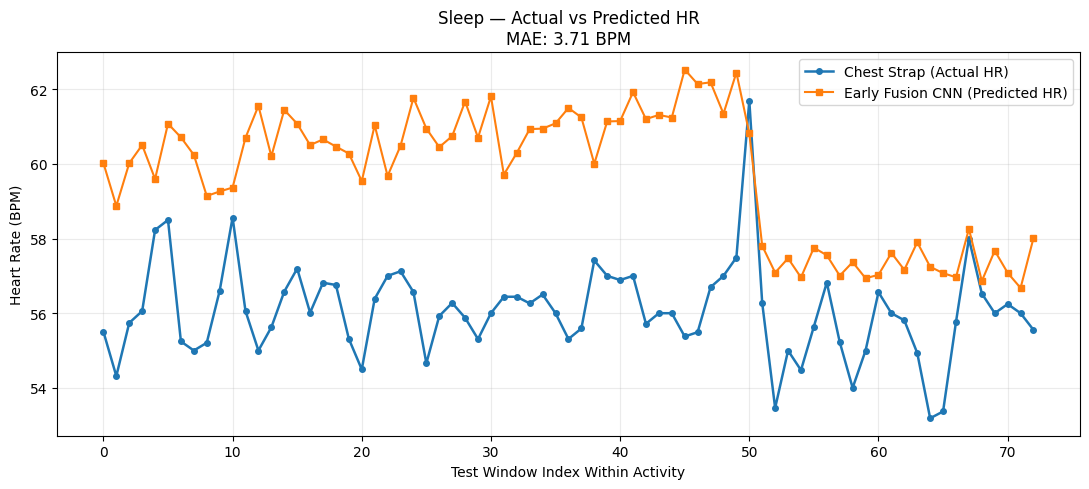

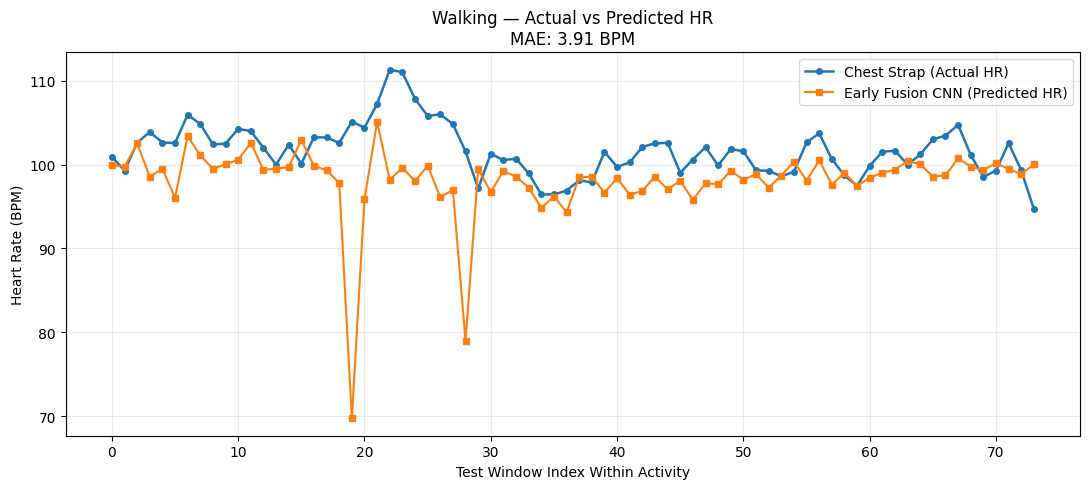

In [29]:
# Actual vs Predicted HR by Activity — Early Fusion CNN

for activity in ACTIVITY_ORDER:

    mask = test_activity == activity

    if not np.any(mask):
        continue

    actual_hr = y_test[mask]
    predicted_hr = y_pred_fusion[mask]

    x = np.arange(len(actual_hr))
    mae = np.mean(np.abs(actual_hr - predicted_hr))

    plt.figure(figsize=(11, 5))

    plt.plot(
        x, actual_hr, "o-",
        label="Chest Strap (Actual HR)",
        linewidth=1.8, markersize=4
    )

    plt.plot(
        x, predicted_hr, "s-",
        label="Early Fusion CNN (Predicted HR)",
        linewidth=1.5, markersize=4
    )

    plt.xlabel("Test Window Index Within Activity")
    plt.ylabel("Heart Rate (BPM)")

    plt.title(
        f"{activity.replace('_', ' ')} — Actual vs Predicted HR\n"
        f"MAE: {mae:.2f} BPM"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

plt.savefig(
    f"../results/figures/early_fusion_actual_vs_predicted_{activity.lower()}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()